# Task 2 — Predictive modeling of customer bookings

Objective: predict whether a customer completes a booking (`booking_complete`) and identify which variables drive that decision.

Notebook structure:
1. Exploratory data analysis
2. Data preparation and feature engineering
3. Model training: comparison of class-balancing techniques
4. Hyperparameter tuning
5. Evaluation with cross-validation and a hold-out test set
6. Feature importance
7. Conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

## 1. Exploratory data analysis

In [2]:
df = pd.read_csv("/Users/usuario/Downloads/data/customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  str    
 2   trip_type              50000 non-null  str    
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  str    
 7   route                  50000 non-null  str    
 8   booking_origin         50000 non-null  str    
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.3 MB


Column descriptions:

- `num_passengers`: number of passengers travelling
- `sales_channel`: sales channel the booking was made on
- `trip_type`: trip type (RoundTrip, OneWay, CircleTrip)
- `purchase_lead`: number of days between the booking date and the travel date
- `length_of_stay`: number of days spent at the destination
- `flight_hour`: hour of flight departure
- `flight_day`: day of the week of flight departure
- `route`: origin → destination flight route
- `booking_origin`: country from which the booking was made
- `wants_extra_baggage`, `wants_preferred_seat`, `wants_in_flight_meals`: additional services requested in the booking
- `flight_duration`: total flight duration (hours)
- `booking_complete`: flag indicating whether the booking was completed (target variable)

In [4]:
mapping = {"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7}
df["flight_day"] = df["flight_day"].map(mapping)
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


### Missing values

In [5]:
df.isnull().sum()

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

The dataset contains no missing values.

### Target distribution

booking_complete
0    42522
1     7478
Name: count, dtype: int64
booking_complete
0    0.8504
1    0.1496
Name: proportion, dtype: float64


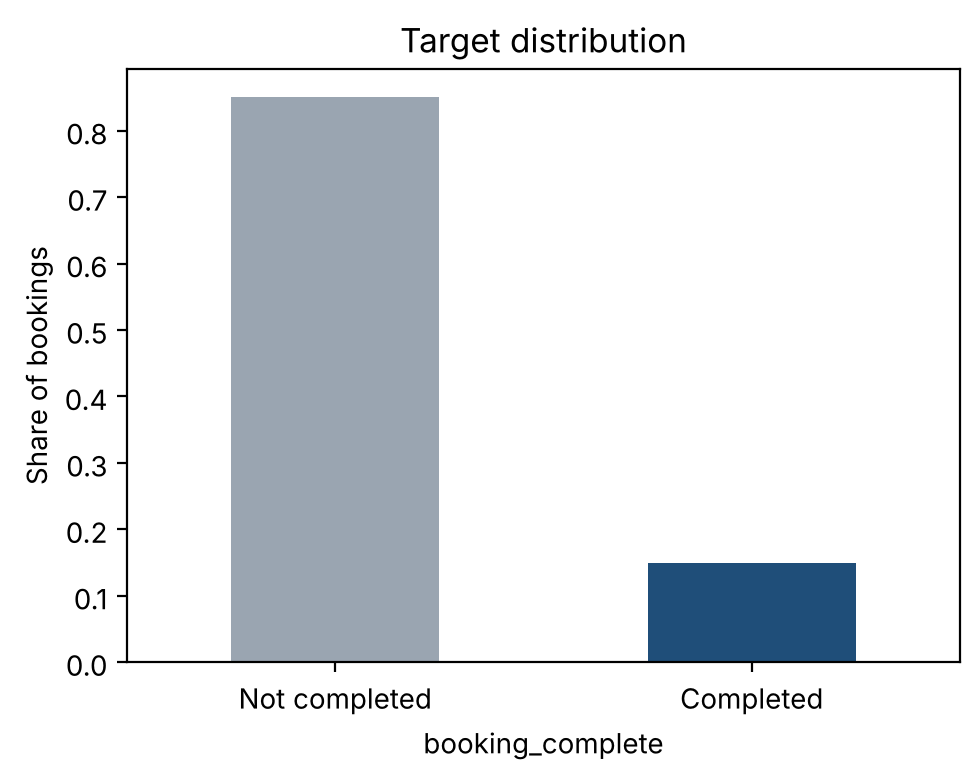

In [6]:
print(df["booking_complete"].value_counts())
print(df["booking_complete"].value_counts(normalize=True).round(4))

ax = df["booking_complete"].value_counts(normalize=True).sort_index().plot.bar(color=["#9aa5b1", "#1f4e79"], figsize=(5, 4))
ax.set_xticklabels(["Not completed", "Completed"], rotation=0)
ax.set_ylabel("Share of bookings")
ax.set_title("Target distribution")
plt.tight_layout(); plt.show()

The positive class represents approximately 15% of observations. Accuracy is not an appropriate metric in this context, since a model that always predicts "not completed" would score around 85%. ROC AUC, precision, recall and F1 for the positive class are therefore used, and class-balancing techniques are evaluated.

### Booking rate by categorical variable

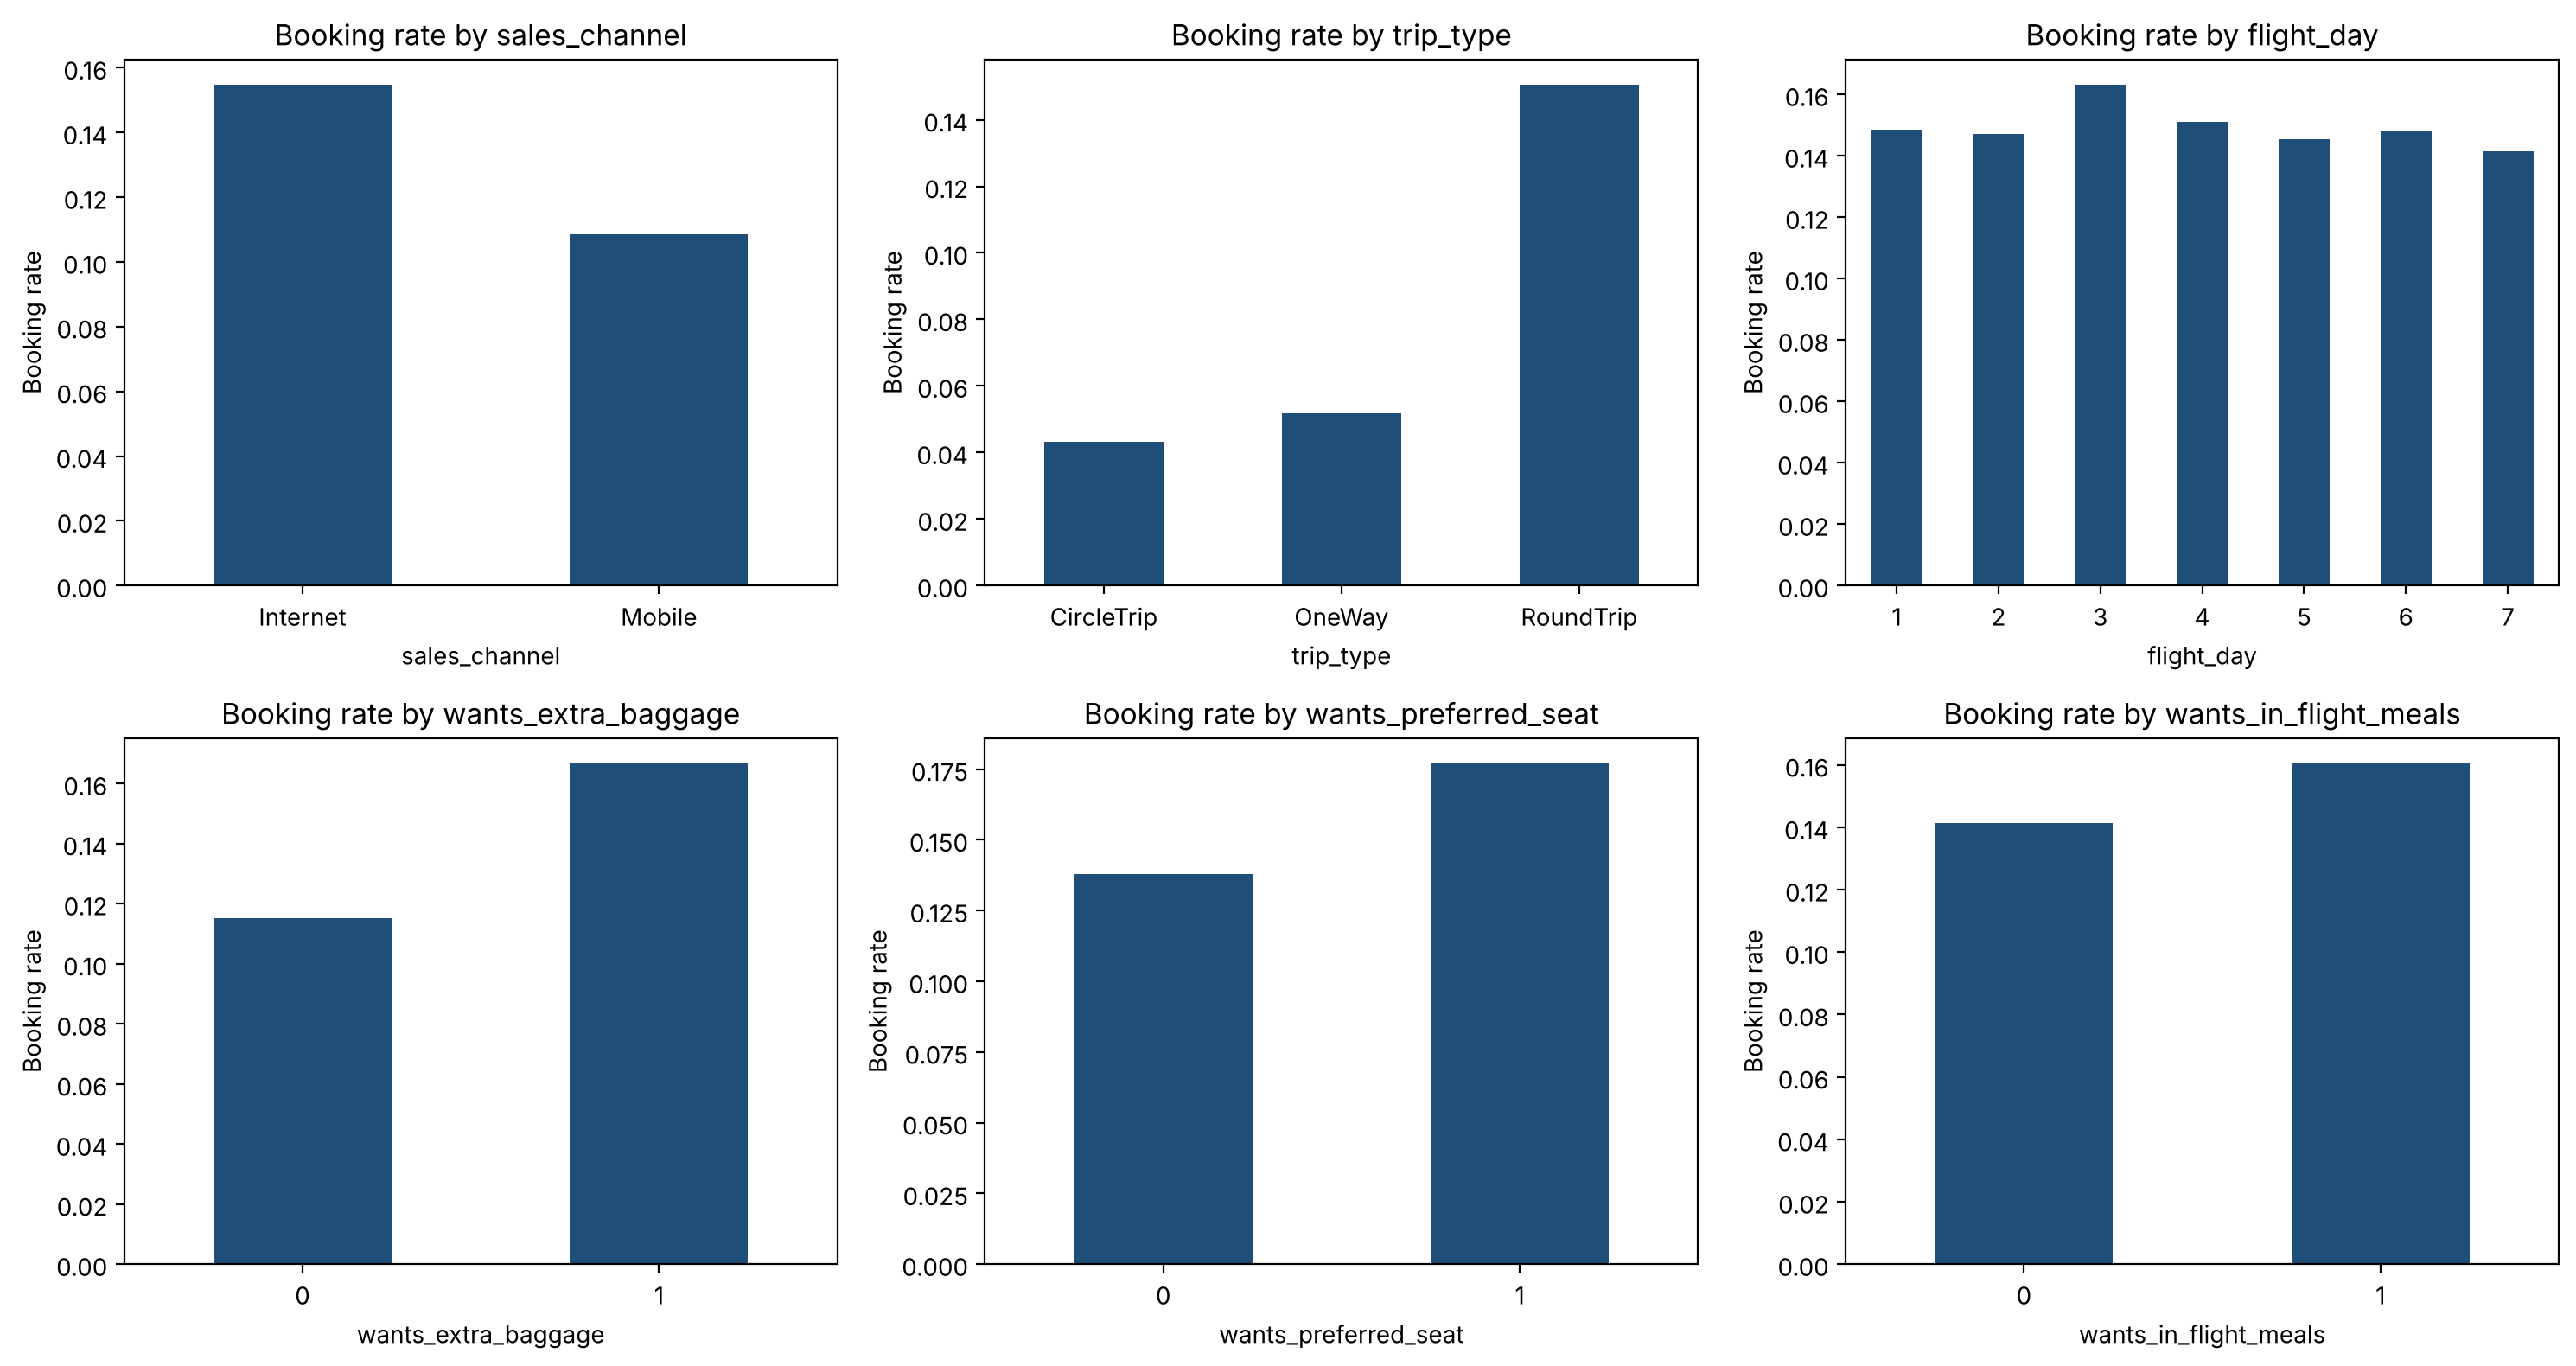

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["sales_channel", "trip_type", "flight_day",
                                  "wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]):
    df.groupby(col)["booking_complete"].mean().plot.bar(ax=ax, color="#1f4e79")
    ax.set_title(f"Booking rate by {col}"); ax.set_ylabel("Booking rate"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

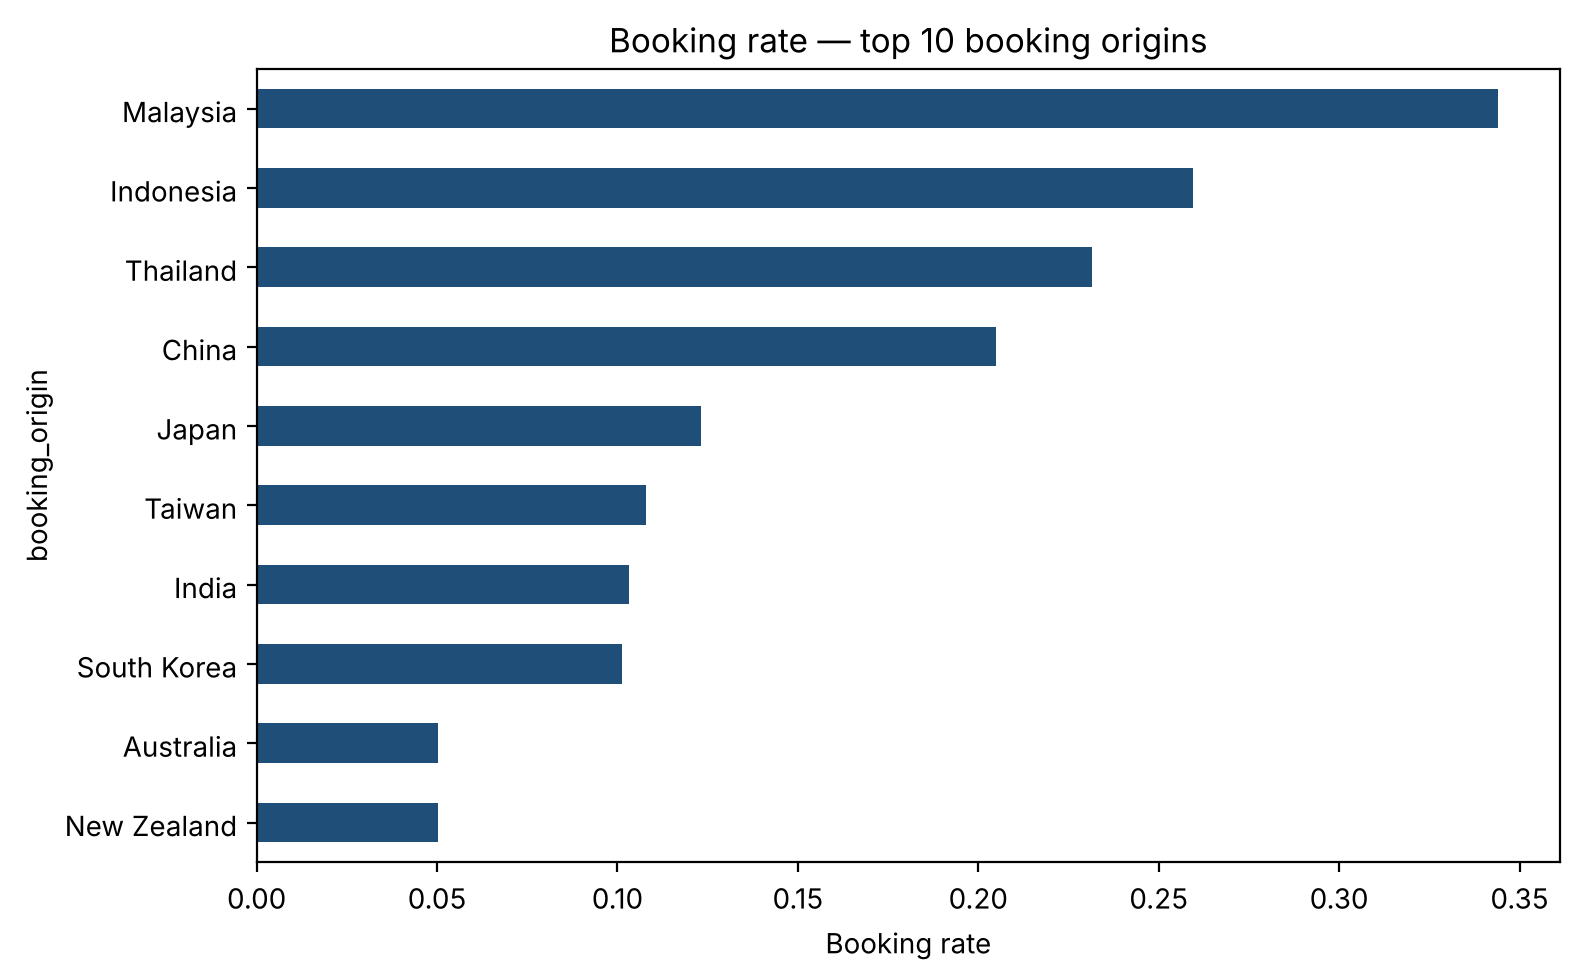

Distinct routes: 799 | Distinct booking origins: 104


In [8]:
top_origins = df["booking_origin"].value_counts().head(10).index
(df[df["booking_origin"].isin(top_origins)]
   .groupby("booking_origin")["booking_complete"].mean().sort_values()
   .plot.barh(figsize=(8, 5), color="#1f4e79", title="Booking rate — top 10 booking origins"))
plt.xlabel("Booking rate"); plt.tight_layout(); plt.show()
print("Distinct routes:", df["route"].nunique(), "| Distinct booking origins:", df["booking_origin"].nunique())

### Outliers

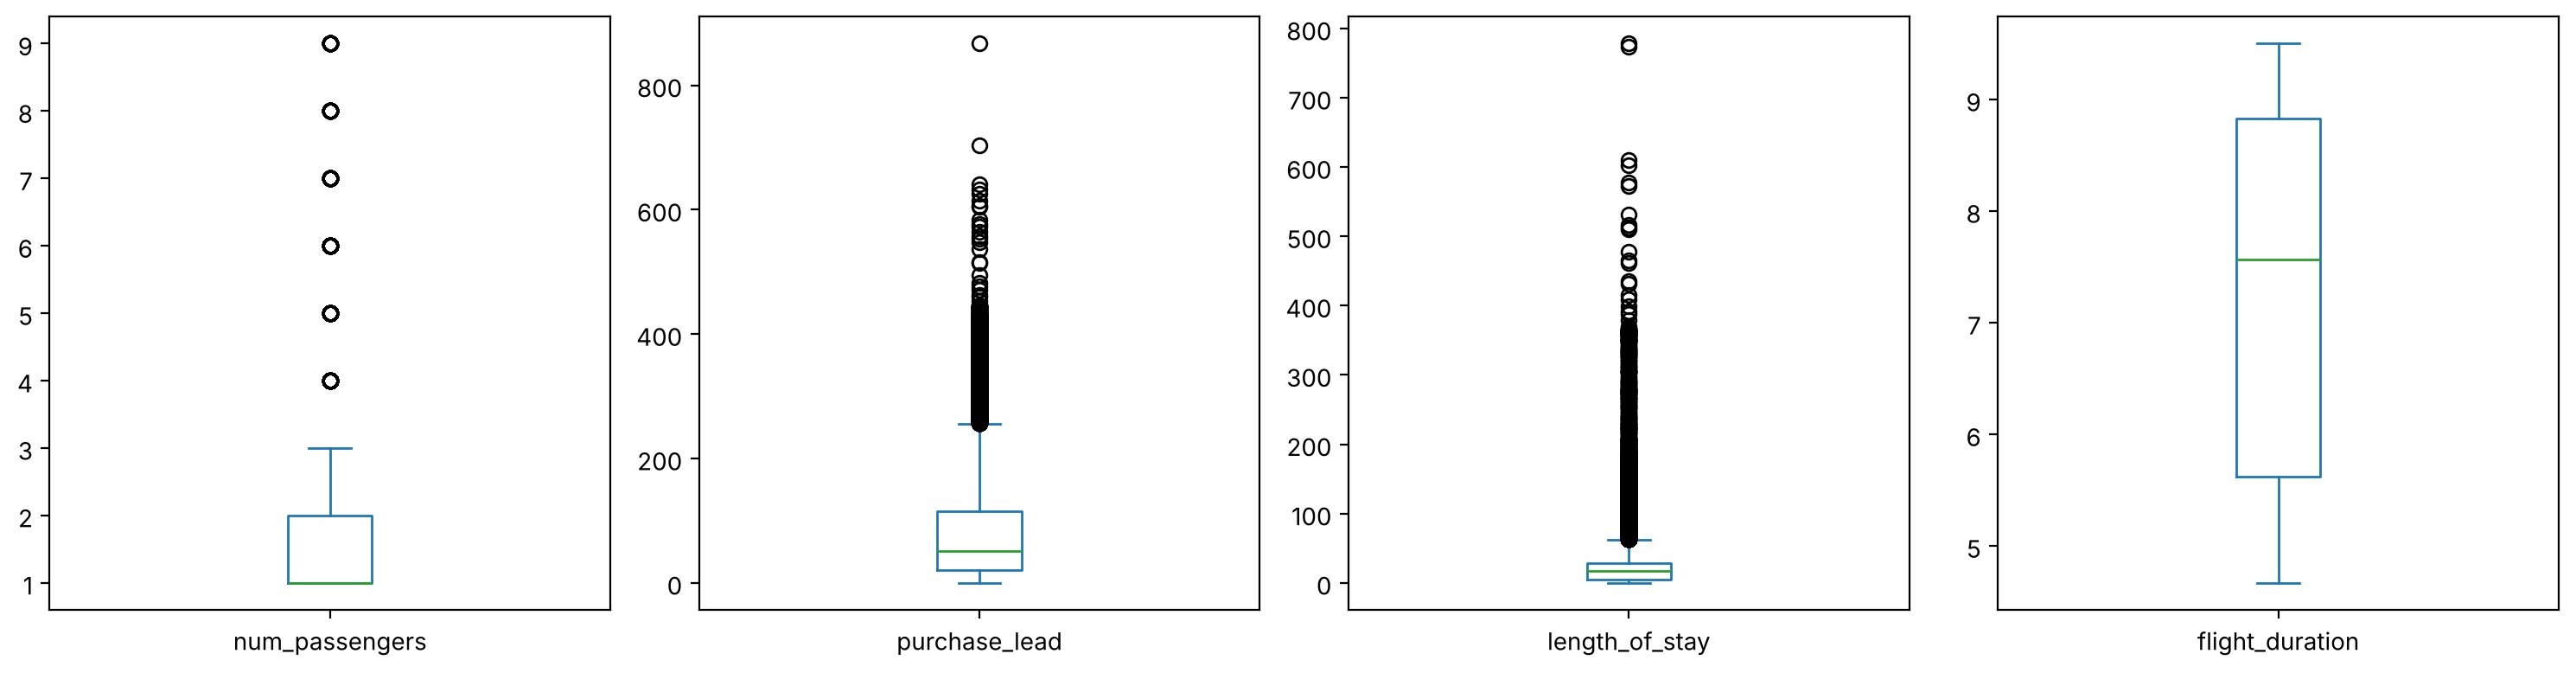

num_passengers: 2903 values outside the IQR range
purchase_lead: 3456 values outside the IQR range


length_of_stay: 3807 values outside the IQR range
flight_duration: 0 values outside the IQR range


In [9]:
num_cols = ["num_passengers", "purchase_lead", "length_of_stay", "flight_duration"]
df[num_cols].plot(kind="box", subplots=True, layout=(1, 4), figsize=(15, 4))
plt.tight_layout(); plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n} values outside the IQR range")

Extreme values of `purchase_lead` and `length_of_stay` reflect genuine customer behaviour (bookings made far in advance or long stays) rather than data-entry errors. Random Forest is robust to outliers because it splits on thresholds, so these values are **neither imputed nor removed**. Log-transformed versions of these variables are created during feature engineering to reduce skewness.

The IQR rule is not applied to binary variables or to the target: for `booking_complete`, Q1 = Q3 = 0, so every completed booking would be flagged as an outlier.

### Multicollinearity (VIF)

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_cols = [c for c in df.select_dtypes(include="number").columns if c != "booking_complete"]
vif = pd.DataFrame({"Variable": vif_cols,
                    "VIF": [variance_inflation_factor(df[vif_cols].values, i) for i in range(len(vif_cols))]})
vif.sort_values("VIF", ascending=False)

,Variable,VIF
7,wants_in_flight_meals,1.162951
6,wants_preferred_seat,1.140379
5,wants_extra_baggage,1.125453
0,num_passengers,1.088589
2,length_of_stay,1.076595
1,purchase_lead,1.064312
8,flight_duration,1.058010
3,flight_hour,1.002833
4,flight_day,1.002282


VIF is computed excluding the target variable. Values above 10 would indicate high multicollinearity. All values are close to 1. Multicollinearity does not affect Random Forest's predictive performance, although highly correlated variables may share importance.

## 2. Data preparation and feature engineering

In [11]:
df_fe = df.copy()

# Number of additional services requested (0 to 3)
df_fe["extras_total"] = df_fe[["wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]].sum(axis=1)

# Weekend departure flag
df_fe["is_weekend"] = df_fe["flight_day"].isin([6, 7]).astype(int)

# Log transformation of skewed variables
df_fe["log_purchase_lead"] = np.log1p(df_fe["purchase_lead"])
df_fe["log_length_of_stay"] = np.log1p(df_fe["length_of_stay"])

# Route: origin and destination airports
df_fe["route_origin"] = df_fe["route"].str[:3]
df_fe["route_dest"] = df_fe["route"].str[3:]

# Frequency encoding for high-cardinality variables (instead of ~900 one-hot columns)
for col in ["route", "booking_origin", "route_origin", "route_dest"]:
    df_fe[col + "_freq"] = df_fe[col].map(df_fe[col].value_counts(normalize=True))

df_model = pd.get_dummies(df_fe.drop(columns=["route", "booking_origin", "route_origin", "route_dest",
                                              "purchase_lead", "length_of_stay"]),
                          columns=["sales_channel", "trip_type"], drop_first=True, dtype=int)
df_model.head()

,num_passengers,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,extras_total,is_weekend,log_purchase_lead,log_length_of_stay,route_freq,booking_origin_freq,route_origin_freq,route_dest_freq,sales_channel_Mobile,trip_type_OneWay,trip_type_RoundTrip
0,2,7,6,1,0,0,5.52,0,1,1,5.572154,2.995732,0.0004,0.02148,0.05698,0.0025,0,0,1
1,1,3,6,0,0,0,5.52,0,0,1,4.727388,3.044522,0.0004,0.02148,0.05698,0.0025,0,0,1
2,2,17,3,1,1,0,5.52,0,2,0,5.497168,3.135494,0.0004,0.02540,0.05698,0.0025,0,0,1
3,1,4,6,0,0,1,5.52,0,1,1,4.574711,3.465736,0.0004,0.02148,0.05698,0.0025,0,0,1
4,2,15,3,1,0,1,5.52,0,2,0,4.234107,3.135494,0.0004,0.02540,0.05698,0.0025,0,0,1


New features created:

| Feature | Description |
|---|---|
| `extras_total` | Number of additional services requested |
| `is_weekend` | Flight departs on Saturday or Sunday |
| `log_purchase_lead`, `log_length_of_stay` | Log transformation to reduce skewness |
| `route_origin_freq`, `route_dest_freq` | Frequency of the origin and destination airports |
| `route_freq`, `booking_origin_freq` | Frequency of the route and the booking country |

No standardisation is applied, since tree-based models are not sensitive to feature scale.

In [12]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df_model.drop(columns="booking_complete")
y = df_model["booking_complete"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of class 1 — train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (40000, 18) | Test: (10000, 18)
Share of class 1 — train: 0.1495 | test: 0.1496


## 3. Comparison of class-balancing techniques

Five alternatives are compared using 5-fold stratified cross-validation on the training set. Resampling is applied inside an `imblearn` `Pipeline`, so it only affects the training data of each fold and no information leaks into the validation folds.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.ensemble import BalancedRandomForestClassifier

rf_params = dict(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
metrics = ["roc_auc", "precision", "recall", "f1"]

models = {
    "RF (no balancing)": RandomForestClassifier(**rf_params),
    "RF class_weight": RandomForestClassifier(class_weight="balanced", **rf_params),
    "RF + undersampling": Pipeline([("rus", RandomUnderSampler(random_state=RANDOM_STATE)),
                                    ("rf", RandomForestClassifier(**rf_params))]),
    "RF + oversampling": Pipeline([("ros", RandomOverSampler(random_state=RANDOM_STATE)),
                                   ("rf", RandomForestClassifier(**rf_params))]),
    "Balanced RF": BalancedRandomForestClassifier(sampling_strategy="all", replacement=True,
                                                  bootstrap=False, **rf_params),
}

results = {}
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    results[name] = {m: s["test_" + m].mean() for m in metrics}

comparison = pd.DataFrame(results).T.round(3)
comparison

,roc_auc,precision,recall,f1
RF (no balancing),0.780,0.525,0.055,0.100
RF class_weight,0.783,0.340,0.610,0.436
RF + undersampling,0.774,0.282,0.758,0.411
RF + oversampling,0.781,0.372,0.473,0.417
Balanced RF,0.782,0.314,0.687,0.431


## 4. Hyperparameter tuning

In [14]:
from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
    BalancedRandomForestClassifier(n_estimators=200, sampling_strategy="all", replacement=True,
                                   bootstrap=False, random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions={"max_depth": [10, 15, 20, None],
                         "min_samples_leaf": [1, 3, 5, 10],
                         "max_features": ["sqrt", 0.5]},
    n_iter=10, cv=cv, scoring="roc_auc", random_state=RANDOM_STATE)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best ROC AUC (CV):", round(search.best_score_, 3))

Best parameters: {'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}
Best ROC AUC (CV): 0.787


## 5. Evaluation

### Cross-validation of the final model

In [15]:
cv_scores = cross_validate(best_model, X_train, y_train, cv=cv, scoring=metrics)
cv_summary = pd.DataFrame({m: [cv_scores["test_" + m].mean(), cv_scores["test_" + m].std()] for m in metrics},
                          index=["mean", "std"]).round(3)
cv_summary

,roc_auc,precision,recall,f1
mean,0.787,0.321,0.685,0.437
std,0.004,0.004,0.013,0.005


### Hold-out test set

              precision    recall  f1-score   support

           0      0.933     0.749     0.831      8504
           1      0.327     0.693     0.444      1496

    accuracy                          0.740     10000
   macro avg      0.630     0.721     0.637     10000
weighted avg      0.842     0.740     0.773     10000

Test ROC AUC: 0.796


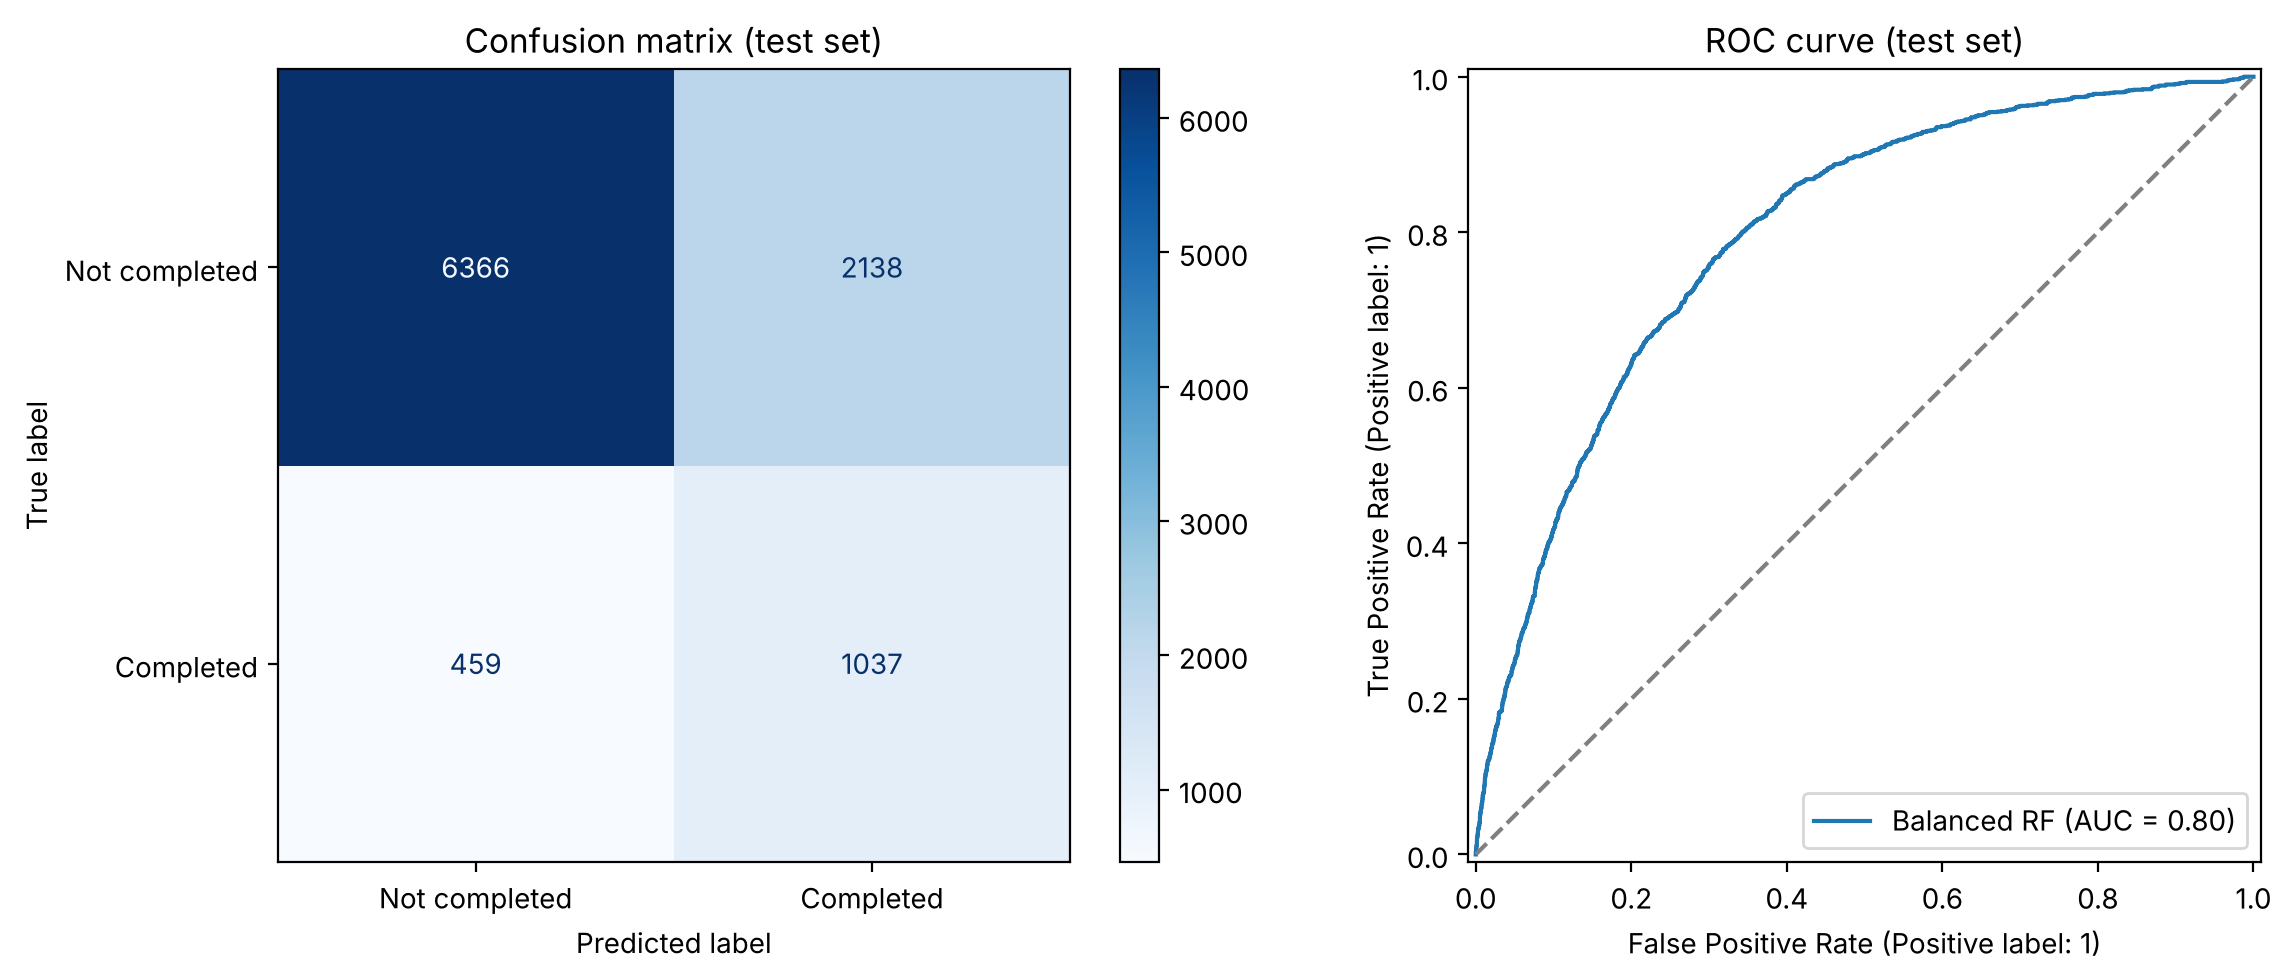

In [16]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=3))
print("Test ROC AUC:", round(roc_auc_score(y_test, y_prob), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Not completed", "Completed"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="Balanced RF")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.show()

## 6. Feature importance

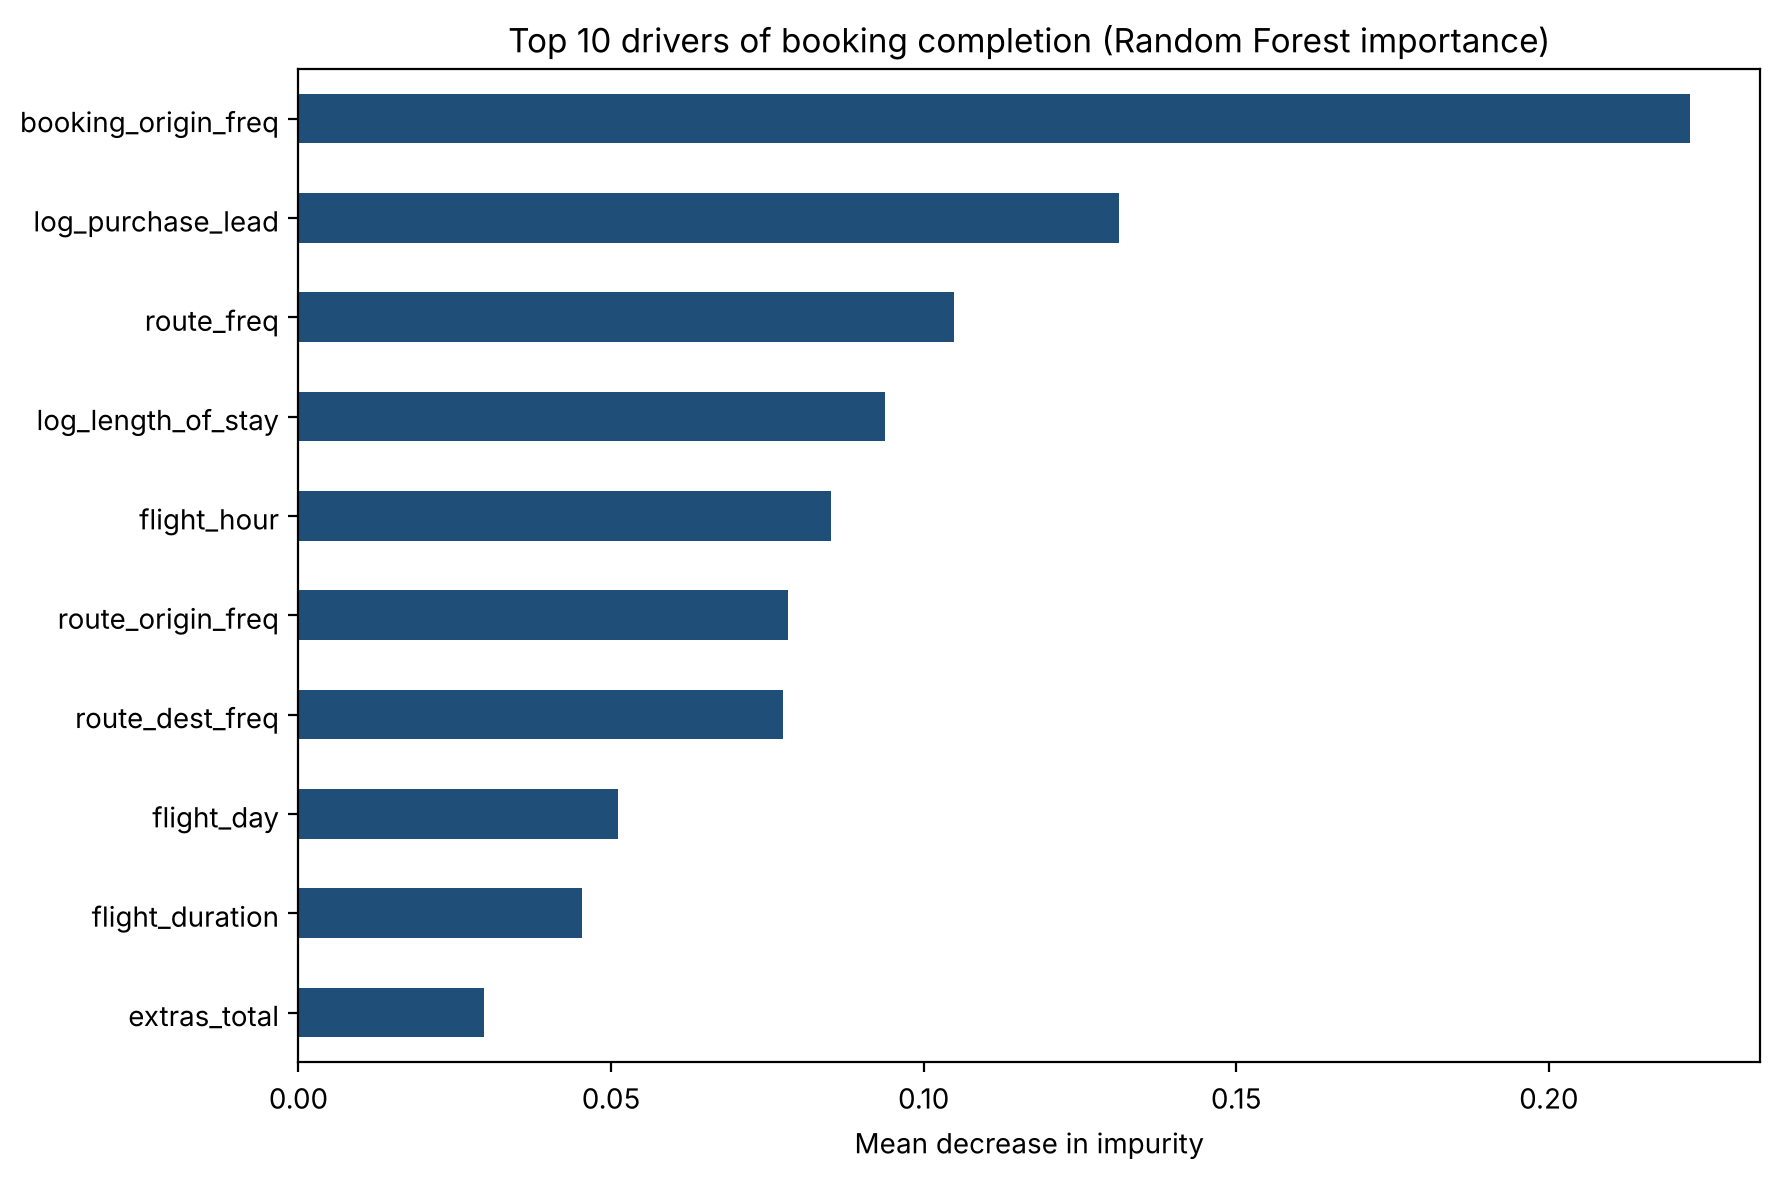

booking_origin_freq      0.2226
log_purchase_lead        0.1312
route_freq               0.1048
log_length_of_stay       0.0938
flight_hour              0.0851
route_origin_freq        0.0783
route_dest_freq          0.0774
flight_day               0.0512
flight_duration          0.0453
extras_total             0.0297
num_passengers           0.0236
sales_channel_Mobile     0.0133
wants_extra_baggage      0.0130
wants_preferred_seat     0.0119
wants_in_flight_meals    0.0111
is_weekend               0.0071
trip_type_RoundTrip      0.0003
trip_type_OneWay         0.0001
dtype: float64

In [17]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
imp.tail(10).plot.barh(ax=ax, color="#1f4e79")
ax.set_title("Top 10 drivers of booking completion (Random Forest importance)")
ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=200); plt.show()
imp.sort_values(ascending=False).round(4)

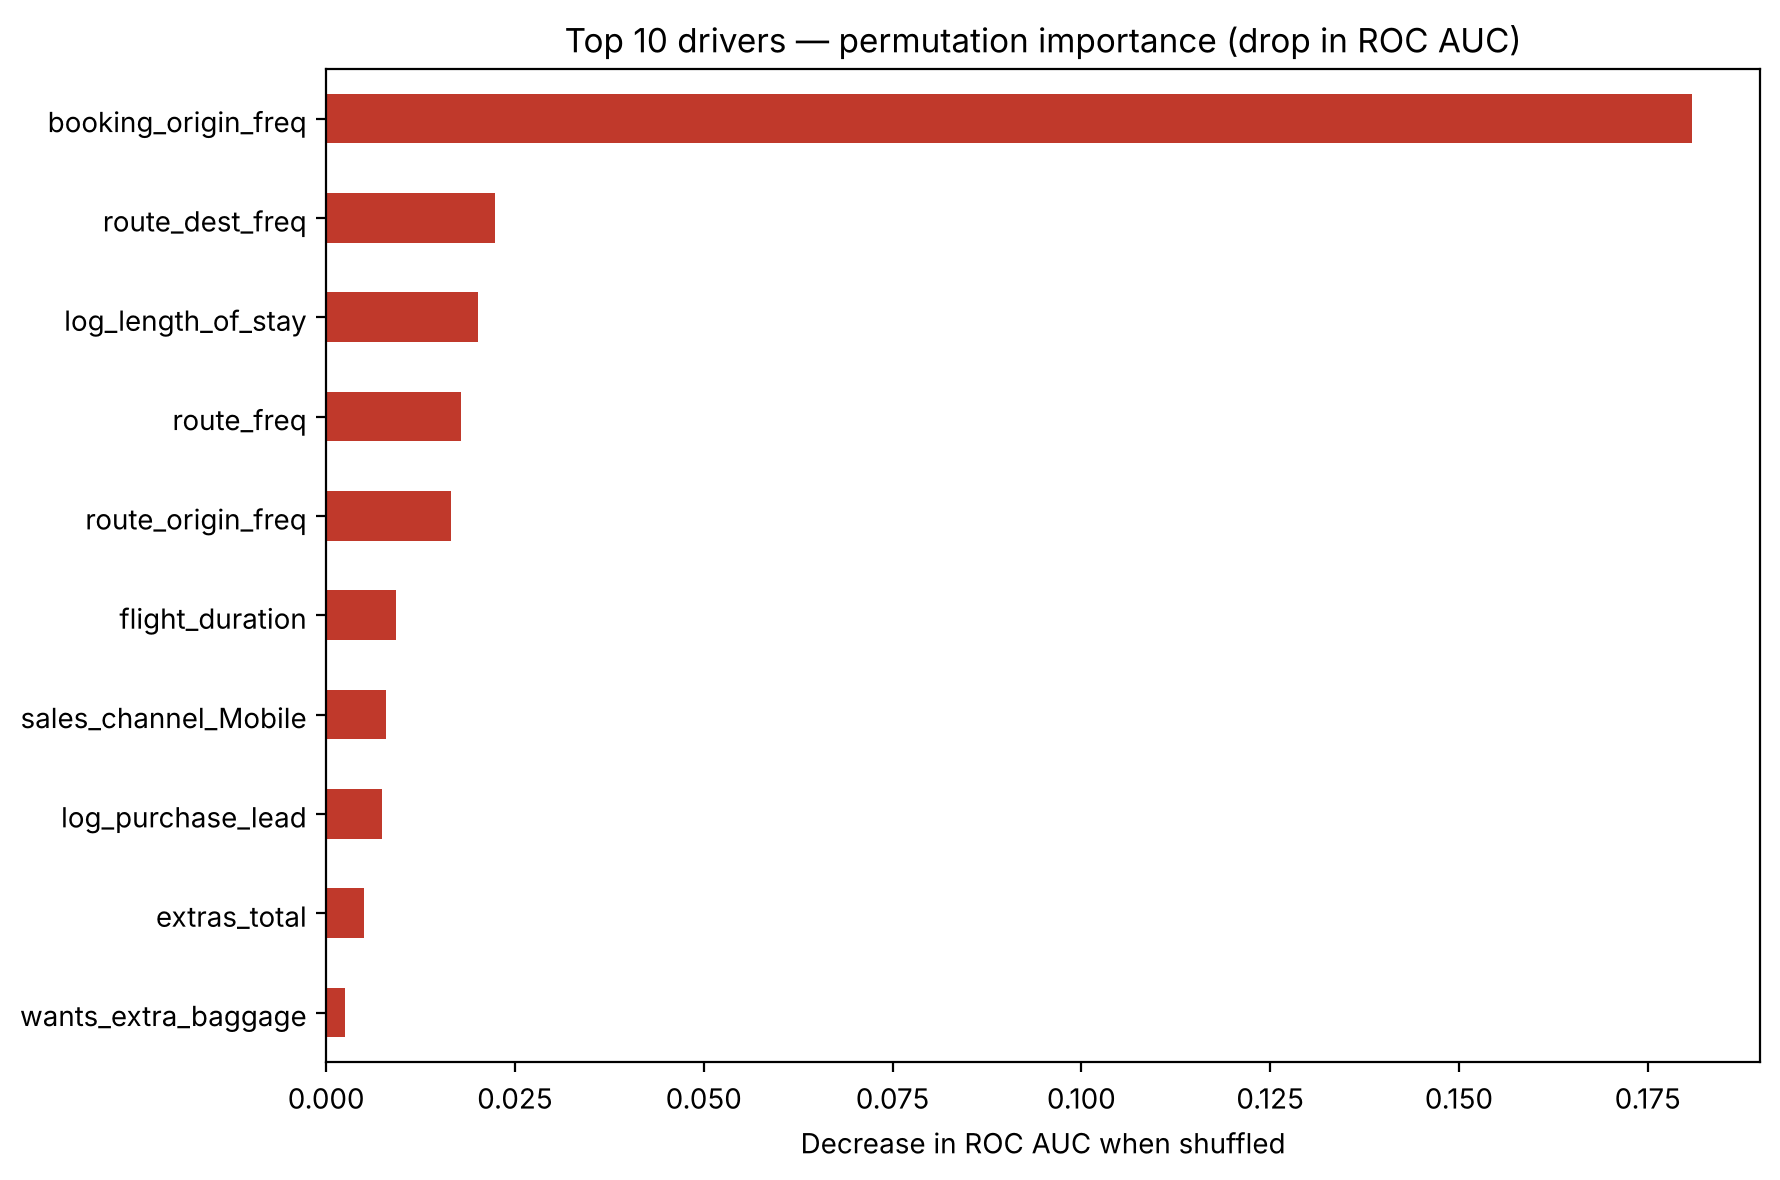

In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
perm_imp.tail(10).plot.barh(ax=ax, color="#c0392b")
ax.set_title("Top 10 drivers — permutation importance (drop in ROC AUC)")
ax.set_xlabel("Decrease in ROC AUC when shuffled")
plt.tight_layout(); plt.savefig("permutation_importance.png", dpi=200); plt.show()

Impurity-based importance tends to favour continuous variables or those with many distinct values. Permutation importance, computed on the test set, measures how much ROC AUC drops when each variable is shuffled and provides a more robust reading. Both are shown for comparison.

## 7. Conclusions

**Model performance**

- The final model is a Balanced Random Forest (`max_depth=None`, `min_samples_leaf=5`, `max_features=0.5`), selected after comparing five class-balancing strategies.
- 5-fold stratified cross-validation: ROC AUC = 0.787 ± 0.004; positive-class recall = 0.685; precision = 0.321; F1 = 0.437.
- Hold-out test set: ROC AUC = 0.796; the model identifies 69% of the bookings that are completed.
- Without balancing, the Random Forest reaches a similar ROC AUC (0.780) but detects only 5.5% of completed bookings, which confirms the need to address class imbalance.
- Positive-class precision is moderate: roughly one in three customers flagged as likely buyers completes the booking. For marketing use, the decision threshold can be adjusted according to the cost of contacting a customer versus the cost of a lost sale.

**Drivers of booking completion**

1. **Booking origin (country)** is by far the most influential factor under both importance measures.
2. **Route and origin/destination airports**: conversion varies substantially across markets.
3. **Length of stay** and **purchase lead time** describe the type of trip and the customer's planning stage.
4. **Flight hour and flight duration** provide additional information about the trip profile.
5. Additional services and sales channel make a smaller contribution.

**Recommendations**

- Prioritise marketing actions by booking market and route, where most of the predictive power is concentrated.
- Design differentiated communications according to purchase lead time and length of stay.
- As a future improvement, incorporate price, availability and browsing-behaviour data, which would likely increase model precision.